# Part 2: Exploratory data analysis (EDA)

This notebook looks at the clean table from `01_cleaning.ipynb` before any modelling. Each section ends with a short note on what it means for the models (R3, R4) or for the report.

**How numbers are computed**
- Inside one system we weight by `W_FSTUWT`. When the six systems are pooled we use `SENWT`, so every system counts equally.
- Anything involving maths is computed once per plausible value and averaged over the 10.
- These are associations, not causes.

**Where each part comes from**

| Section | Based on |
|---|---|
| 2.1, 2.2, 2.3 (1, 3), 2.5 (1), 2.6 (1), 2.7 (1, 4), 2.9 (1), 2.11 | Mohamed, `02_eda` |
| 2.3 (2, 6), 2.6 (1), 2.7 (1), 2.9 (2) | Annie, `03_eda_observations` sections 2, 3, 6, 8 |
| 2.2 (1), 2.3 (5, 6), 2.7 (2) | Fathah, `fathah_eda_cleaning` |
| 2.2 standard errors, 2.3 (4, 5), 2.4, 2.5 (2), 2.6 (2, 3), 2.7 (3), 2.8, 2.9 (2) between systems, 2.10 | New: not in any team notebook |

## Setup

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

DATA = Path("../data")
FIGS = Path("outputs/figures")
FIGS.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(DATA / "clean/pisa6_clean.parquet")
roles = json.loads((DATA / "clean/columns.json").read_text())
GROUPS = roles["feature_groups"]
FEATURES = [c for cols in GROUPS.values() for c in cols]
PV = roles["targets"]["regression"]
BELOW = roles["targets"]["classification"]
REP = roles["weights"]["replicates"]

SYSTEMS = ["ARE", "SAU", "QAT", "JOR", "MAR", "PSE"]
NAMES = {"ARE": "UAE", "SAU": "Saudi Arabia", "QAT": "Qatar", "JOR": "Jordan", "MAR": "Morocco", "PSE": "Palestine"}
by_sys = {s: df[df["CNT"] == s] for s in SYSTEMS}

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
GREEN, GREY = "#2F7D6D", "#B8C4C0"
print(df.shape)

(61775, 158)


In [2]:
def wmean(x, w):
    ok = x.notna()
    return np.average(x[ok], weights=w[ok])

def pv_mean(d, cols=PV, w="W_FSTUWT"):
    # weighted mean for each plausible value, then the average of the 10
    return np.mean([wmean(d[c], d[w]) for c in cols])

def wcorr(x, y, w):
    ok = x.notna() & y.notna()
    c = np.cov(x[ok], y[ok], aweights=w[ok])
    return c[0, 1] / np.sqrt(c[0, 0] * c[1, 1])

def wquantile(x, w, q):
    order = np.argsort(x.to_numpy())
    cum = np.cumsum(w.to_numpy()[order]) / w.sum()
    return x.to_numpy()[order][np.searchsorted(cum, q)]

def save(fig, name):
    fig.savefig(FIGS / f"{name}.png", bbox_inches="tight", dpi=150)

# 2.1) Sample and weights
*From Mohamed, section 1.*

PISA doesn't sample each country in proportion to its size. The UAE sampled extra students so it can report per emirate. The weight `W_FSTUWT` is roughly how many real 15-year-olds each student stands for.

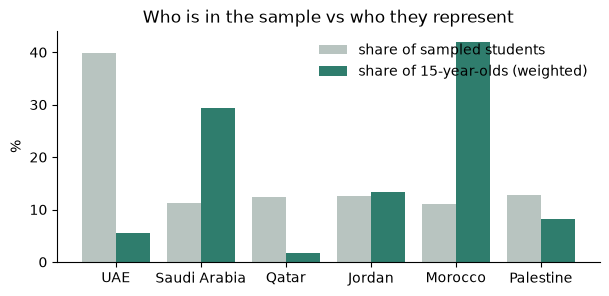

,students,sample_%,population_%
CNT,,,
ARE,24600,39.8,5.6
SAU,6928,11.2,29.3
QAT,7676,12.4,1.7
JOR,7799,12.6,13.3
MAR,6867,11.1,42.0
PSE,7905,12.8,8.2


In [3]:
sample = pd.DataFrame({
    "students": df.groupby("CNT").size(),
    "sample_%": df.groupby("CNT").size() / len(df) * 100,
    "population_%": df.groupby("CNT")["W_FSTUWT"].sum() / df["W_FSTUWT"].sum() * 100,
}).loc[SYSTEMS]

fig, ax = plt.subplots(figsize=(7, 3))
x = np.arange(len(SYSTEMS))
ax.bar(x - 0.2, sample["sample_%"], 0.4, color=GREY, label="share of sampled students")
ax.bar(x + 0.2, sample["population_%"], 0.4, color=GREEN, label="share of 15-year-olds (weighted)")
ax.set_xticks(x, [NAMES[s] for s in SYSTEMS])
ax.set_ylabel("%")
ax.legend(frameon=False)
ax.set_title("Who is in the sample vs who they represent")
save(fig, "01_sample_vs_population")
plt.show()
sample.round(1)

> **Note:** without weights most numbers would describe the UAE (40% of the sample, 6% of the population). With `W_FSTUWT`, Morocco and Saudi Arabia are 71% of the pooled population, so we pool with `SENWT` instead.

# 2.2) Target: maths scores and the Level 2 line
*From Mohamed, section 2, and Fathah's weighted averages. Standard errors are new.*

## 1) Means and % below Level 2, with standard errors
Standard errors use the 80 replicate weights (Fay's method, k = 0.5) and are combined over the 10 plausible values with Rubin's rules, which is how the OECD computes them.

In [4]:
def mean_se(d, cols):
    W = d[["W_FSTUWT"] + REP].to_numpy()
    est, var = [], []
    for c in cols:
        m = d[c].to_numpy() @ W / W.sum(axis=0)     # full weight + 80 replicates
        est.append(m[0])
        var.append(((m[1:] - m[0]) ** 2).sum() / 20)  # 1 / (80 * 0.5^2)
    est = np.array(est)
    return est.mean(), np.sqrt(np.mean(var) + 1.1 * est.var(ddof=1))

rows = {}
for s in SYSTEMS:
    m, m_se = mean_se(by_sys[s], PV)
    p, p_se = mean_se(by_sys[s], BELOW)
    rows[NAMES[s]] = {"maths": m, "maths_se": m_se, "below_L2_%": p * 100, "below_L2_se": p_se * 100}
target = pd.DataFrame(rows).T
target.to_csv("outputs/target_by_system.csv")
target.round(1)

,maths,maths_se,below_L2_%,below_L2_se
UAE,431.1,0.9,49.0,0.5
Saudi Arabia,388.8,1.8,70.0,1.1
Qatar,414.1,1.1,56.5,0.8
Jordan,361.2,2.0,82.8,1.2
Morocco,364.8,3.4,81.6,1.7
Palestine,365.7,1.8,79.9,0.9


> **Note:** the means match the OECD's published figures (UAE 431, Jordan 361) and Fathah's numbers. Standard errors are small, 0.9 to 3.4 points, but Jordan, Morocco and Palestine (361–366) are within two standard errors of each other, so the report shouldn't rank them.

## 2) Score distributions
All 10 plausible values, each with a tenth of the student's weight. The dashed line is the Level 2 cut-off (420).

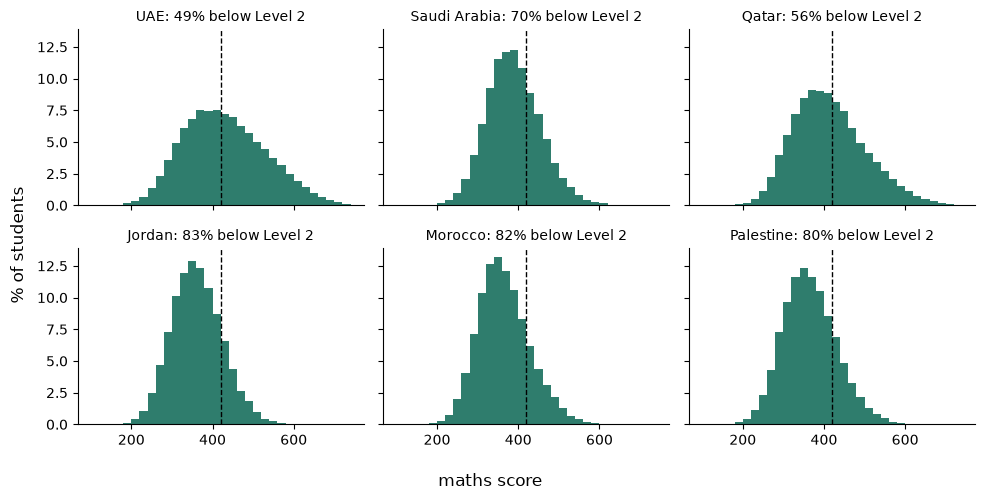

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(10, 5), sharex=True, sharey=True)
bins = np.arange(100, 760, 20)
for ax, s in zip(axes.flat, SYSTEMS):
    d = by_sys[s]
    scores = d[PV].to_numpy().ravel()
    w = np.repeat(d["W_FSTUWT"].to_numpy(), 10)
    ax.hist(scores, bins=bins, weights=w / w.sum() * 100, color=GREEN)
    ax.axvline(420.07, color="black", lw=1, ls="--")
    ax.set_title(f"{NAMES[s]}: {target.loc[NAMES[s], 'below_L2_%']:.0f}% below Level 2", fontsize=10)
fig.supxlabel("maths score")
fig.supylabel("% of students")
fig.tight_layout()
save(fig, "02_maths_distributions")
plt.show()

## 3) Class balance

In [6]:
print(f"below Level 2, pooled with W_FSTUWT: {pv_mean(df, BELOW) * 100:.1f}%")
print(f"below Level 2, pooled with SENWT:    {pv_mean(df, BELOW, 'SENWT') * 100:.1f}%")
print(f"label changes across the 10 PVs:     {df[BELOW].nunique(axis=1).gt(1).mean():.1%}")

below Level 2, pooled with W_FSTUWT: 76.0%
below Level 2, pooled with SENWT:    70.0%


label changes across the 10 PVs:     32.2%


> **Note:** the class we want to flag is the **majority**. A model that says "below Level 2" for everyone already gets about 70–76% accuracy, so we judge models on ROC-AUC, PR-AUC, balanced accuracy and recall for both classes. A third of students change label between plausible values, which is why models run on all 10.

# 2.3) Missing values
## 1) Missing by system
*From Mohamed, section 3, and Annie, section 2.*

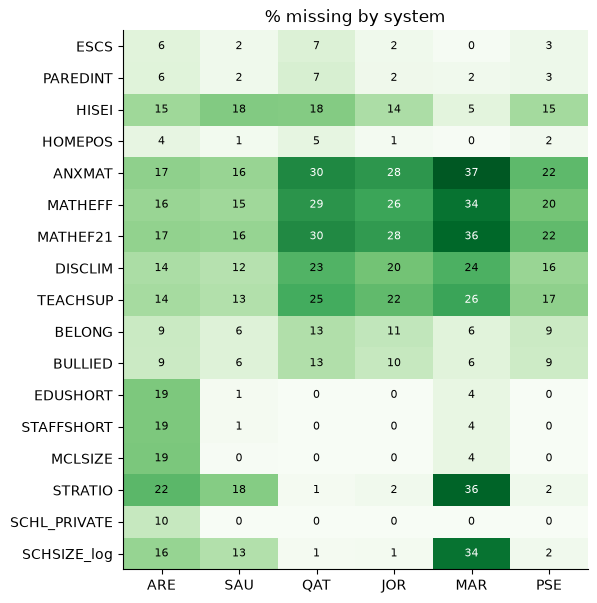

In [7]:
miss = df[FEATURES].isna().groupby(df["CNT"]).mean().mul(100).loc[SYSTEMS].T

fig, ax = plt.subplots(figsize=(6, 7))
ax.imshow(miss, cmap="Greens", vmin=0, vmax=40, aspect="auto")
ax.set_xticks(range(len(SYSTEMS)), SYSTEMS)
ax.set_yticks(range(len(FEATURES)), FEATURES)
for i in range(len(FEATURES)):
    for j in range(len(SYSTEMS)):
        v = miss.iloc[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white" if v > 25 else "black")
ax.set_title("% missing by system")
save(fig, "03_missing_by_system")
plt.show()

> **Note:** maths attitudes (15–37%) and classroom questions (12–26%) are skipped most, worst in Morocco, Qatar and Jordan. School variables are almost complete except in the UAE (empty school questionnaires) and Morocco (a third without school size or ratio).

## 2) Which answers go missing together
*From Annie, section 2.*

In [8]:
STUDENT_FEATS = ["ESCS", "PAREDINT", "HISEI", "HOMEPOS", "ANXMAT", "MATHEFF", "MATHEF21",
                 "DISCLIM", "TEACHSUP", "BELONG", "BULLIED"]
mask = df[STUDENT_FEATS].isna()
patterns = mask.apply(lambda row: ", ".join(row.index[row]) or "none missing", axis=1)
patterns.value_counts().head(6).to_frame("students")

,students
none missing,41562
"ANXMAT, MATHEFF, MATHEF21, DISCLIM, TEACHSUP",3675
HISEI,3328
"ESCS, PAREDINT, HISEI, HOMEPOS, ANXMAT, MATHEFF, MATHEF21, DISCLIM, TEACHSUP, BELONG, BULLIED",1700
"ANXMAT, MATHEFF, MATHEF21",1589
"ANXMAT, MATHEFF, MATHEF21, DISCLIM, TEACHSUP, BELONG, BULLIED",993


> **Note:** the most common gap is one block: the three maths-attitude scales and the two classroom scales together. Parts 4 and 5 look at who these students are.

## 3) Does a blank answer tell us something?
*From Mohamed, section 4.*

Maths score of students who left each predictor blank minus those who answered it. Systems with fewer than 30 blanks are skipped.

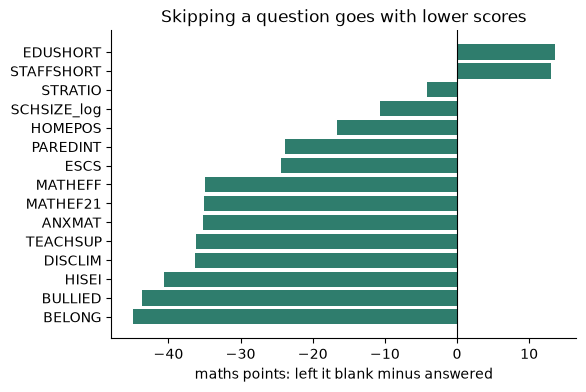

,ARE,SAU,QAT,JOR,MAR,PSE,average
ESCS,-43.0,-13.0,-33.0,-19.0,-22.0,-17.0,-24.0
PAREDINT,-41.0,-14.0,-30.0,-20.0,-23.0,-15.0,-24.0
HISEI,-72.0,-27.0,-49.0,-41.0,-20.0,-35.0,-41.0
HOMEPOS,-38.0,-9.0,-22.0,-11.0,NaN,-3.0,-17.0
ANXMAT,-62.0,-22.0,-51.0,-28.0,-18.0,-29.0,-35.0
MATHEFF,-61.0,-23.0,-52.0,-28.0,-20.0,-26.0,-35.0
MATHEF21,-60.0,-23.0,-51.0,-29.0,-19.0,-29.0,-35.0
DISCLIM,-61.0,-26.0,-51.0,-28.0,-23.0,-29.0,-36.0
TEACHSUP,-62.0,-24.0,-51.0,-28.0,-22.0,-29.0,-36.0
BELONG,-62.0,-30.0,-56.0,-39.0,-46.0,-37.0,-45.0


In [9]:
def missing_gap(d, col):
    blank = d[col].isna()
    if blank.sum() < 30:
        return np.nan
    return pv_mean(d[blank]) - pv_mean(d[~blank])

gap = pd.DataFrame({s: {c: missing_gap(by_sys[s], c) for c in FEATURES} for s in SYSTEMS})
gap["average"] = gap.mean(axis=1)
avg = gap.loc[gap[SYSTEMS].notna().sum(axis=1) >= 3, "average"].sort_values()

fig, ax = plt.subplots(figsize=(6, 4))
ax.barh(avg.index, avg, color=GREEN)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("maths points: left it blank minus answered")
ax.set_title("Skipping a question goes with lower scores")
save(fig, "04_missing_score_gap")
plt.show()
gap.round(0)

> **Note:** for every student question, students who left it blank score lower, by roughly 17 to 45 points. So blanks are **not random** and the `_missing` flags from cleaning carry real information. School variables go the other way in the UAE: students whose school sent no questionnaire score higher.

## 4) Who skips
*New.*

Students with all five attitude and classroom answers blank, against everyone else. Pooled with `SENWT`.

In [10]:
block = GROUPS["maths_attitudes"] + GROUPS["classroom"]
is_blank = df[block].isna().all(axis=1)

def profile(d):
    return pd.Series({
        "share_%": d["SENWT"].sum() / df["SENWT"].sum() * 100,
        "girls_%": wmean((d["ST004D01T"] == 1).astype(float), d["SENWT"]) * 100,
        "ESCS": wmean(d["ESCS"], d["SENWT"]),
        "effort_1_10": wmean(d["EFFORT1"], d["SENWT"]),
        "maths": pv_mean(d, PV, "SENWT"),
        "below_L2_%": pv_mean(d, BELOW, "SENWT") * 100,
    })

print("students with the whole block blank:", is_blank.sum())
pd.DataFrame({"answered": profile(df[~is_blank]), "block blank": profile(df[is_blank])}).T.round(2)

students with the whole block blank: 9258


,share_%,girls_%,ESCS,effort_1_10,maths,below_L2_%
answered,84.27,54.35,-0.53,8.07,393.08,67.48
block blank,15.73,33.19,-0.90,7.91,358.39,83.36


> **Note:** the students who skip are mostly boys, poorer, and far more often below Level 2. Their test effort is about the same, so it isn't simply "didn't care". Missingness depends on who the student is, which is one more reason to keep the flags and impute inside the folds rather than drop rows.

## 5) Skipped, or never got there?
*New, with Fathah's `ICTDISTR` finding.*

`REACHED_ATTITUDES` (from cleaning) says whether the student opened the attitude screens at all. `ICT_MODULE` says whether the system ran the optional ICT questionnaire.

In [11]:
reach = pd.DataFrame({
    "block_blank": is_blank.groupby(df["CNT"]).sum(),
    "never_reached_%": (1 - df[is_blank].groupby("CNT")["REACHED_ATTITUDES"].mean()) * 100,
    "ICT_module": df.groupby("CNT")["ICT_MODULE"].max().map({1: "yes", 0: "no"}),
}).loc[SYSTEMS]

print(f"never reached the attitude screens: {1 - df.loc[is_blank, 'REACHED_ATTITUDES'].mean():.1%} of the blank group,"
      f" {1 - df.loc[~is_blank, 'REACHED_ATTITUDES'].mean():.1%} of everyone else")
reach.round(1)

never reached the attitude screens: 22.2% of the blank group, 0.1% of everyone else


,block_blank,never_reached_%,ICT_module
CNT,,,
ARE,3056,31.9,no
SAU,720,11.1,yes
QAT,1648,16.6,no
JOR,1286,4.1,yes
MAR,1503,39.2,yes
PSE,1045,8.1,no


> **Note:** about a fifth of the blank group never reached those screens (most in Morocco and the UAE). They ran out of time or stopped, they didn't skip. The rest opened the screens and left them blank. The UAE, Qatar and Palestine didn't run the ICT questionnaire, which is why Fathah found `ICTDISTR` 100% missing there. It's a design gap, not student behaviour.

## 6) What dropping incomplete rows would cost
*From Fathah and Annie.*

In [12]:
complete = df[FEATURES].notna().all(axis=1)
print(f"students with all 17 answered: {complete.mean():.1%}")
(100 - complete.groupby(df["CNT"]).mean().loc[SYSTEMS] * 100).round(1).to_frame("lost_if_dropped_%")

students with all 17 answered: 55.9%


,lost_if_dropped_%
CNT,
ARE,44.2
SAU,44.0
QAT,40.0
JOR,39.5
MAR,64.5
PSE,34.6


> **Note:** complete-case analysis would drop over 40% of students, nearly two thirds in Morocco, and (from parts 3 and 4) mostly the weaker students. So we keep everyone.

# 2.4) Response quality
*New.*

Share of flagged students and their maths gap against the rest, per system (`W_FSTUWT`). Flags come from cleaning: low effort (4 or less out of 10), speeding (under 1 second per anxiety item), straightlining (same answer to every anxiety item).

In [13]:
def quality(d):
    out = {}
    for flag in ["LOW_EFFORT", "SPEEDING", "STRAIGHTLINE"]:
        known = d[d[flag].notna()]
        out[f"{flag.lower()}_%"] = wmean(known[flag], known["W_FSTUWT"]) * 100
        out[f"{flag.lower()}_gap"] = pv_mean(known[known[flag] == 1]) - pv_mean(known[known[flag] == 0])
    return pd.Series(out)

quality_df = pd.DataFrame({NAMES[s]: quality(by_sys[s]) for s in SYSTEMS}).T
quality_df.round(1)

,low_effort_%,low_effort_gap,speeding_%,speeding_gap,straightline_%,straightline_gap
UAE,5.4,-27.8,9.5,-77.8,37.8,-13.7
Saudi Arabia,2.8,-19.9,3.4,3.7,39.4,-10.4
Qatar,6.7,-20.9,11.3,-59.6,38.0,-20.7
Jordan,5.8,-8.6,11.0,-10.5,29.0,-14.6
Morocco,3.5,1.8,2.9,5.0,25.8,-7.4
Palestine,4.7,-5.9,9.2,-21.7,27.5,-10.8


> **Note:** speeding is the clearest warning sign. Speeders score 78 points lower in the UAE and 60 in Qatar, but about the same as everyone else in Saudi Arabia and Morocco. Low effort is rare (3–7%) and costs 20–28 points in the UAE, Saudi Arabia and Qatar, nothing in Morocco. Straightlining is common (26–39%, 7–21 points lower), but all six anxiety items point the same way, so a genuinely calm or anxious student can straightline honestly. We keep everyone and use `SPEEDING` for one sensitivity run later.

# 2.5) Distributions and outliers
## 1) Predictor distributions
*From Mohamed, section 5.* Six systems pooled with `SENWT`.

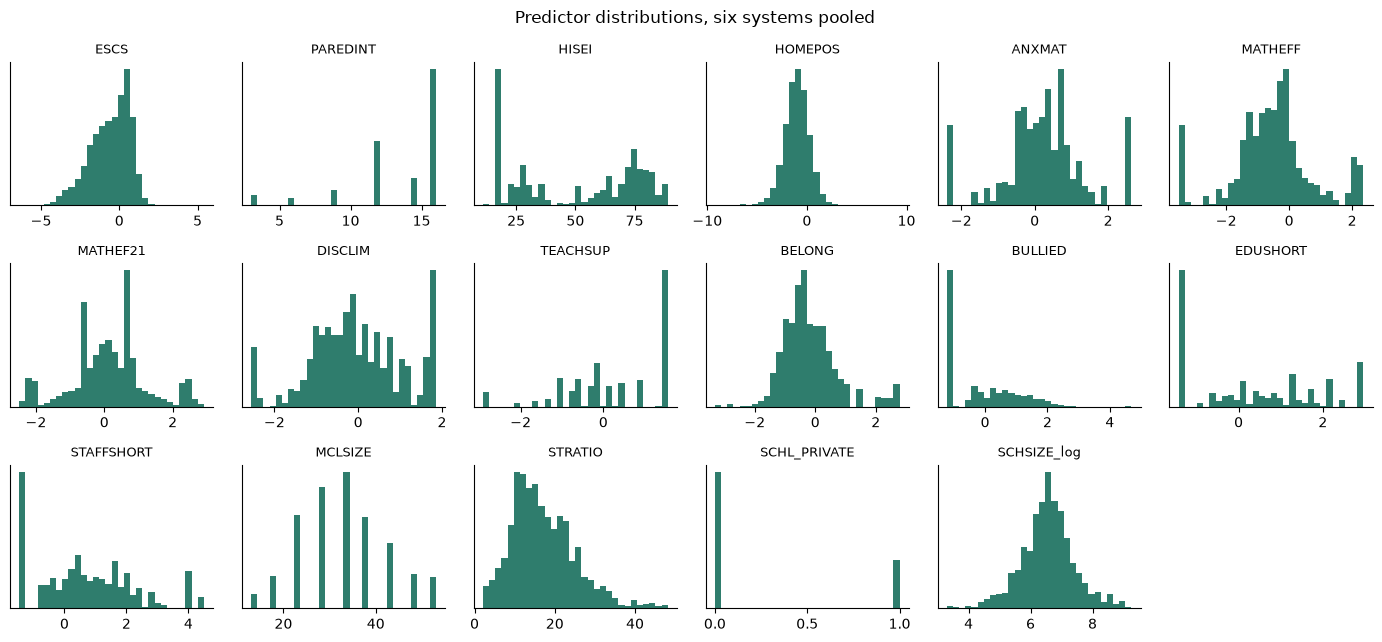

In [14]:
fig, axes = plt.subplots(3, 6, figsize=(14, 6.5))
for ax, c in zip(axes.flat, FEATURES):
    d = df[df[c].notna()]
    ax.hist(d[c], bins=30, weights=d["SENWT"], color=GREEN)
    ax.set_title(c, fontsize=9)
    ax.set_yticks([])
axes.flat[-1].set_visible(False)
fig.suptitle("Predictor distributions, six systems pooled")
fig.tight_layout()
save(fig, "05_feature_distributions")
plt.show()

## 2) Outliers and pile-ups
*New, the IQR rule from the ML2 notebook (1.3).*

In [15]:
rows = {}
for c in [c for c in FEATURES if c != "SCHL_PRIVATE"]:
    x = df[c].dropna()
    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1
    rows[c] = {
        "outside_1.5_IQR_%": ((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).mean() * 100,
        "outside_3_IQR_%": ((x < q1 - 3 * iqr) | (x > q3 + 3 * iqr)).mean() * 100,
        "at_min_%": (x == x.min()).mean() * 100,
        "at_max_%": (x == x.max()).mean() * 100,
    }
pd.DataFrame(rows).T.round(1)

,outside_1.5_IQR_%,outside_3_IQR_%,at_min_%,at_max_%
ESCS,1.6,0.0,0.0,0.0
PAREDINT,2.8,0.0,2.8,59.2
HISEI,0.0,0.0,0.1,0.1
HOMEPOS,2.0,0.4,0.0,0.0
ANXMAT,12.2,0.0,1.1,1.2
MATHEFF,15.2,0.0,0.0,0.1
MATHEF21,1.0,0.0,0.0,0.0
DISCLIM,0.0,0.0,0.0,0.5
TEACHSUP,0.0,0.0,3.8,34.9
BELONG,5.8,0.0,0.0,0.0


> **Note:** the 1.5 IQR rule flags up to 15% of self-efficacy and 12% of anxiety, but these are bounded scales built from a few 4-point answers, so the "outliers" are just students at the ends of the scale. At 3 IQR almost nothing is flagged. Several scales pile up at one end (e.g. most students at the top of parents' education and at the bottom of being bullied). We delete nothing. Clipping at the 1st/99th percentile happens inside the training folds.

# 2.6) How the predictors relate to each other
## 1) Correlations
*From Mohamed, section 6, and Annie, section 6.* Weighted, pooled with `SENWT`.

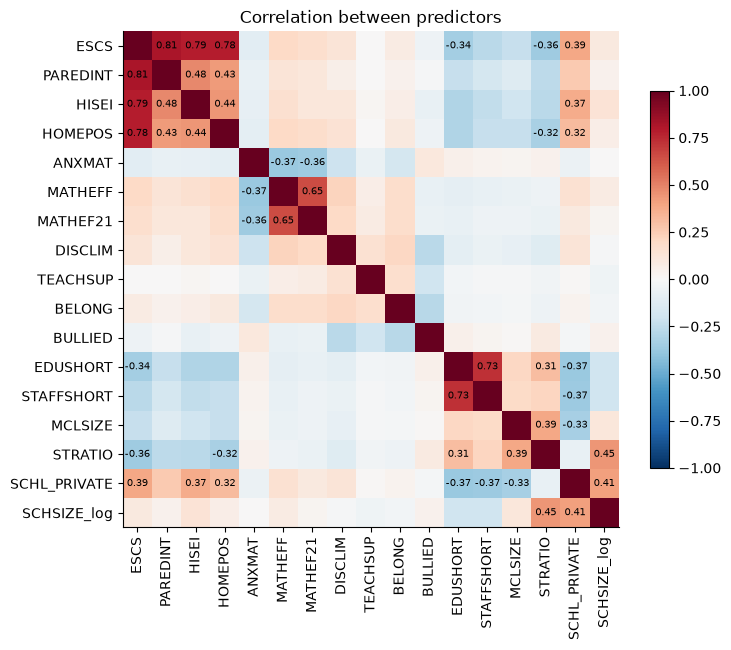

In [16]:
corr = pd.DataFrame({a: {b: wcorr(df[a], df[b], df["SENWT"]) for b in FEATURES} for a in FEATURES})

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=90)
ax.set_yticks(range(len(FEATURES)), FEATURES)
for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        if i != j and abs(corr.iloc[i, j]) >= 0.3:
            ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, shrink=0.7)
ax.set_title("Correlation between predictors")
save(fig, "06_feature_correlations")
plt.show()

## 2) Highly correlated pairs
*New, the ML2 notebook's threshold check (1.4).*

In [17]:
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pairs[pairs.abs() > 0.6].sort_values(ascending=False).round(2).to_frame("r")

r
ESCS     PAREDINT    0.81
         HISEI       0.79
         HOMEPOS     0.78
EDUSHORT STAFFSHORT  0.73
MATHEFF  MATHEF21    0.65

## 3) Multicollinearity (VIF)
*New.*

ESCS is built by the OECD from parents' education, parents' occupation and home possessions, so we check how much of it the three parts explain, then the variance inflation factor (VIF = 1 / (1 − R²) of each predictor on all the others). Unweighted, complete cases.

In [18]:
parts = ["PAREDINT", "HISEI", "HOMEPOS"]
fam = df[["ESCS"] + parts].dropna()
fit = LinearRegression().fit(fam[parts], fam["ESCS"])
print(f"R² of ESCS on its three parts: {fit.score(fam[parts], fam['ESCS']):.6f}")

def vif(cols):
    X = df[cols].dropna()
    out = {}
    for c in cols:
        others = X.drop(columns=c)
        out[c] = 1 / (1 - LinearRegression().fit(others, X[c]).score(others, X[c]))
    return pd.Series(out)

vifs = pd.DataFrame({
    "all 17": vif(FEATURES),
    "without ESCS": vif([c for c in FEATURES if c != "ESCS"]),
    "ESCS, without parts": vif([c for c in FEATURES if c not in parts]),
})
vifs.round(1).astype(object)

R² of ESCS on its three parts: 1.000000


,all 17,without ESCS,"ESCS, without parts"
ANXMAT,1.2,1.2,1.2
BELONG,1.2,1.2,1.2
BULLIED,1.2,1.2,1.2
DISCLIM,1.2,1.2,1.2
EDUSHORT,2.4,2.4,2.4
ESCS,1268519382.4,NaN,1.5
HISEI,220983032.9,1.5,NaN
HOMEPOS,252429089.4,1.5,NaN
MATHEF21,1.9,1.9,1.9
MATHEFF,1.9,1.9,1.9


> **Note:** ESCS is an **exact** weighted combination of its three parts (R² = 1.000). Mohamed's and Annie's correlations (about 0.8) show the overlap but not that it's exact. With all four in one linear model the VIFs explode and the coefficients can't be separated. Drop either side and every VIF is below about 2.5. For logistic regression and naive Bayes we use ESCS alone. Trees and the MLP can keep all four.

# 2.7) Predictors against maths
## 1) Correlation with maths, per system
*From Mohamed, section 7, and Annie, section 8.* Averaged over the 10 PVs, `W_FSTUWT`.

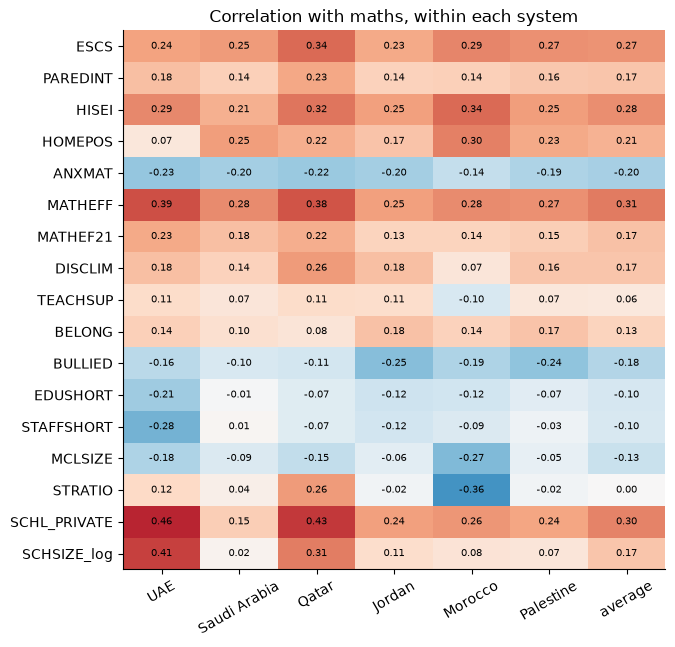

In [19]:
r_sys = pd.DataFrame({NAMES[s]: {c: np.mean([wcorr(by_sys[s][c], by_sys[s][pv], by_sys[s]["W_FSTUWT"]) for pv in PV])
                                  for c in FEATURES} for s in SYSTEMS})
r_sys["average"] = r_sys.mean(axis=1)

fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(r_sys, cmap="RdBu_r", vmin=-0.6, vmax=0.6, aspect="auto")
ax.set_xticks(range(r_sys.shape[1]), r_sys.columns, rotation=30)
ax.set_yticks(range(len(FEATURES)), FEATURES)
for i in range(len(FEATURES)):
    for j in range(r_sys.shape[1]):
        ax.text(j, i, f"{r_sys.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.set_title("Correlation with maths, within each system")
save(fig, "07_feature_maths_correlations")
plt.show()

> **Note:** the strongest single links (about 0.3) are maths self-efficacy, private schooling, parents' occupation and ESCS. School factors matter mostly in the UAE and Qatar, which have big private sectors. A few predictors flip sign between systems. The student-teacher ratio is positive in Qatar and negative in Morocco, so results should be reported per system as well as pooled.

## 2) Maths points per unit
*From Fathah.*

Weighted slope (maths points per one unit of the predictor) in each system, then the average. Units differ: one standard deviation for the indices, one student for class size, one log unit for school size.

In [20]:
def slope(d, c):
    ok = d[c].notna()
    x, w = d.loc[ok, c], d.loc[ok, "W_FSTUWT"]
    return np.mean([np.cov(x, d.loc[ok, pv], aweights=w)[0, 1] / np.cov(x, aweights=w) for pv in PV])

slopes = pd.DataFrame({NAMES[s]: {c: slope(by_sys[s], c) for c in FEATURES} for s in SYSTEMS})
slopes["average"] = slopes.mean(axis=1)
slopes.sort_values("average").round(1)

,UAE,Saudi Arabia,Qatar,Jordan,Morocco,Palestine,average
ANXMAT,-19.5,-10.9,-16.5,-12.1,-9.2,-12.4,-13.4
BULLIED,-13.6,-6.3,-8.5,-13.0,-10.6,-13.6,-10.9
EDUSHORT,-18.0,-0.3,-7.0,-5.5,-6.1,-3.4,-6.7
STAFFSHORT,-20.3,0.4,-5.8,-4.6,-4.2,-1.3,-6.0
MCLSIZE,-2.0,-0.6,-1.6,-0.3,-2.6,-0.4,-1.2
STRATIO,3.2,0.4,4.7,-0.2,-2.3,-0.2,0.9
HISEI,1.5,0.6,1.5,0.6,1.0,0.6,1.0
TEACHSUP,9.6,3.9,8.1,5.4,-5.0,3.8,4.3
PAREDINT,9.7,3.3,9.1,3.3,1.9,4.5,5.3
BELONG,15.6,6.1,7.1,11.8,11.1,12.3,10.7


> **Note:** going to a private school is worth about 59 points on average (95 in the UAE). One standard deviation of ESCS is worth 21 points and of self-efficacy 19, while anxiety costs 13. These are the easiest numbers to quote in the report, as long as we say they are not adjusted for each other.

## 3) Is the relationship straight?
*New.*

η² is the share of maths variance explained by the predictor's decile means. It catches any shape, while r² only catches a straight line. A big gap means a linear model misses signal.

In [21]:
def eta2_vs_r2(c):
    d = df[df[c].notna()]
    deciles = pd.qcut(d[c].rank(method="first"), 10, labels=False)
    w = d["SENWT"]
    e2, r2 = [], []
    for pv in PV:
        y = d[pv]
        mean = np.average(y, weights=w)
        decile_means = (y * w).groupby(deciles).sum() / w.groupby(deciles).sum()
        e2.append(np.average((deciles.map(decile_means) - mean) ** 2, weights=w) / np.average((y - mean) ** 2, weights=w))
        r2.append(wcorr(d[c], y, w) ** 2)
    return pd.Series({"r2": np.mean(r2), "eta2": np.mean(e2)})

shape = pd.DataFrame({c: eta2_vs_r2(c) for c in FEATURES if c != "SCHL_PRIVATE"}).T
shape["gap"] = shape["eta2"] - shape["r2"]
shape.sort_values("gap", ascending=False).round(3)

,r2,eta2,gap
PAREDINT,0.051,0.116,0.065
SCHSIZE_log,0.064,0.111,0.048
BULLIED,0.029,0.068,0.039
ESCS,0.132,0.165,0.033
MCLSIZE,0.035,0.067,0.032
HOMEPOS,0.095,0.122,0.027
DISCLIM,0.041,0.067,0.026
TEACHSUP,0.005,0.030,0.025
MATHEFF,0.114,0.138,0.024
STAFFSHORT,0.043,0.065,0.022


> **Note:** parents' education explains more than twice as much once the shape is free (η² 0.12 vs r² 0.05), and school size, bullying and class size also bend. Tree models and the MLP should pick this up, so we expect them to beat the linear baselines.

## 4) Low achievement by ESCS and self-efficacy quarter
*From Mohamed, section 8.* Quarters are cut within each system.

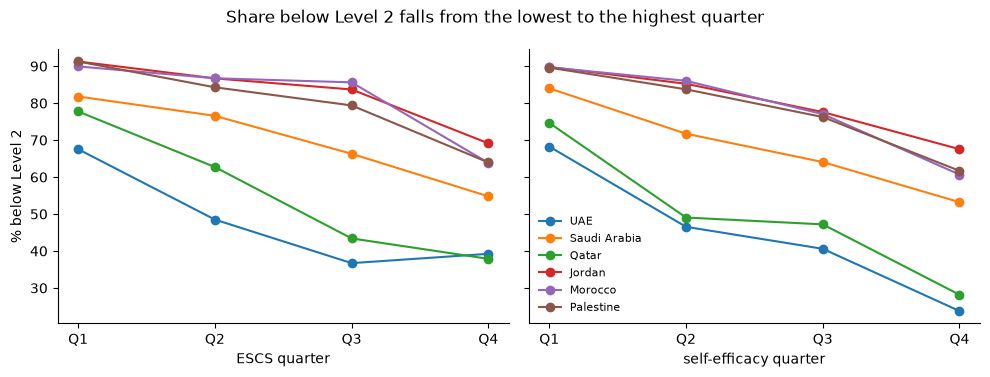

Q1    Q2    Q3    Q4
ESCS    UAE           68.0  49.0  37.0  39.0
        Saudi Arabia  82.0  77.0  66.0  55.0
        Qatar         78.0  63.0  43.0  38.0
        Jordan        91.0  87.0  84.0  69.0
        Morocco       90.0  87.0  86.0  64.0
        Palestine     91.0  84.0  79.0  64.0
MATHEFF UAE           68.0  47.0  41.0  24.0
        Saudi Arabia  84.0  72.0  64.0  53.0
        Qatar         75.0  49.0  47.0  28.0
        Jordan        90.0  85.0  78.0  68.0
        Morocco       90.0  86.0  77.0  61.0
        Palestine     90.0  84.0  76.0  62.0

In [22]:
def below_by_quarter(d, c):
    d = d[d[c].notna()]
    cuts = [wquantile(d[c], d["W_FSTUWT"], q) for q in (0.25, 0.5, 0.75)]
    quarter = np.digitize(d[c], cuts)
    return pd.Series({f"Q{q + 1}": pv_mean(d[quarter == q], BELOW) * 100 for q in range(4)})

escs_q = pd.DataFrame({NAMES[s]: below_by_quarter(by_sys[s], "ESCS") for s in SYSTEMS}).T
eff_q = pd.DataFrame({NAMES[s]: below_by_quarter(by_sys[s], "MATHEFF") for s in SYSTEMS}).T

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, table, title in [(axes[0], escs_q, "ESCS quarter"), (axes[1], eff_q, "self-efficacy quarter")]:
    for name, row in table.iterrows():
        ax.plot(row.index, row, marker="o", label=name)
    ax.set_xlabel(title)
axes[0].set_ylabel("% below Level 2")
axes[1].legend(frameon=False, fontsize=8)
fig.suptitle("Share below Level 2 falls from the lowest to the highest quarter")
fig.tight_layout()
save(fig, "08_below_L2_by_quarter")
plt.show()
pd.concat({"ESCS": escs_q, "MATHEFF": eff_q}).round(0)

> **Note:** in every system the share below Level 2 drops from the poorest to the richest quarter, but even in the richest quarter more than half are below Level 2 in four systems. Self-efficacy gives a gradient at least as steep as ESCS.

# 2.8) What each factor group explains (T15)
*New.*

This is the core of our research question. For each of the five groups: weighted R² of a linear model using that group alone, and how much R² is lost when the group is removed from the full model. Blanks get the median plus a missing flag, so nobody is dropped. This is in-sample and descriptive, not a model result.

all 17 predictors, pooled: R² = 0.365


UAE             0.397
Saudi Arabia    0.186
Qatar           0.380
Jordan          0.256
Morocco         0.311
Palestine       0.256


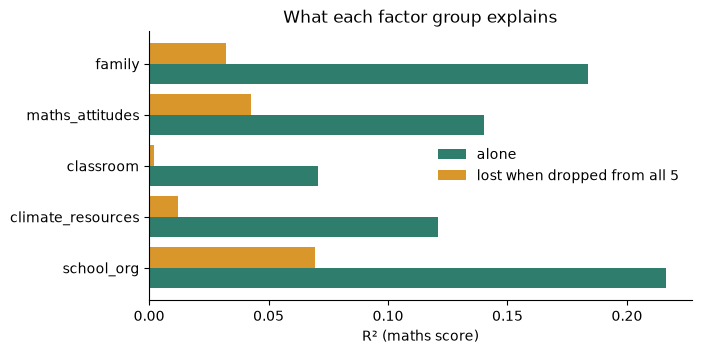

,alone,lost_when_dropped
family,0.184,0.032
maths_attitudes,0.140,0.043
classroom,0.071,0.002
climate_resources,0.121,0.012
school_org,0.216,0.070


In [23]:
def r2(cols, d=df, w="SENWT"):
    X = d[cols].copy()
    for c in cols:
        if X[c].isna().any():
            X[c + "_missing"] = X[c].isna().astype(int)
            X[c] = X[c].fillna(X[c].median())
    return np.mean([LinearRegression().fit(X, d[pv], sample_weight=d[w]).score(X, d[pv], sample_weight=d[w])
                    for pv in PV])

r2_all = r2(FEATURES)
groups = pd.DataFrame({
    "alone": {g: r2(cols) for g, cols in GROUPS.items()},
    "lost_when_dropped": {g: r2_all - r2([c for c in FEATURES if c not in cols]) for g, cols in GROUPS.items()},
})
print(f"all 17 predictors, pooled: R² = {r2_all:.3f}")
print(pd.Series({NAMES[s]: r2(FEATURES, by_sys[s], "W_FSTUWT") for s in SYSTEMS}).round(3).to_string())

fig, ax = plt.subplots(figsize=(7, 3.5))
y = np.arange(len(groups))
ax.barh(y + 0.2, groups["alone"], 0.4, color=GREEN, label="alone")
ax.barh(y - 0.2, groups["lost_when_dropped"], 0.4, color="#D9962B", label="lost when dropped from all 5")
ax.set_yticks(y, groups.index)
ax.invert_yaxis()
ax.set_xlabel("R² (maths score)")
ax.legend(frameon=False)
ax.set_title("What each factor group explains")
save(fig, "09_factor_groups")
plt.show()
groups.round(3)

> **Note:** school organisation explains most on its own and loses most when removed, so it carries information nothing else has. Classroom adds almost nothing once the other groups are in. All 17 together explain 0.365 of maths variance, close to Mohamed's out-of-sample ridge (0.36), so there is little overfitting at this size. The fit is weakest in Saudi Arabia (0.19). This sets the order for the ablations in R3.

# 2.9) Schools and systems
## 1) How much do schools differ?
*From Mohamed, section 9.*

Share of maths variance between schools (school means differ) rather than within them.

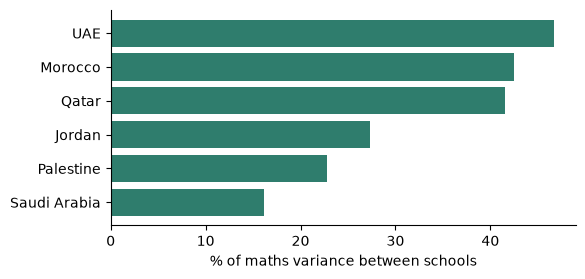

,between_schools_%
Saudi Arabia,16.1
Palestine,22.8
Jordan,27.3
Qatar,41.5
Morocco,42.4
UAE,46.7


In [24]:
def between_schools(d):
    w = d["W_FSTUWT"]
    school_w = w.groupby(d["CNTSCHID"]).sum()
    shares = []
    for pv in PV:
        mean = np.average(d[pv], weights=w)
        school_means = (d[pv] * w).groupby(d["CNTSCHID"]).sum() / school_w
        shares.append(np.average((school_means - mean) ** 2, weights=school_w) / np.average((d[pv] - mean) ** 2, weights=w))
    return np.mean(shares) * 100

between = pd.Series({NAMES[s]: between_schools(by_sys[s]) for s in SYSTEMS}).sort_values()
fig, ax = plt.subplots(figsize=(6, 2.8))
ax.barh(between.index, between, color=GREEN)
ax.set_xlabel("% of maths variance between schools")
save(fig, "10_between_school_share")
plt.show()
between.round(1).to_frame("between_schools_%")

> **Note:** in the UAE, Qatar and Morocco over 40% of the variation lies between schools. If one school had students in both training and test data, the model could partly recognise the school. That's why the folds (`04_folds.ipynb`) hold out whole schools.

## 2) Pooled vs within vs between systems
*From Annie, section 8. The between-system column is new.*

Pooling six very different systems can create or hide relationships. We compare the pooled correlation, the average within-system correlation and the correlation between the six system averages.

In [25]:
rows = {}
for c in ["ESCS", "HOMEPOS", "MATHEFF", "ANXMAT", "TEACHSUP", "SCHSIZE_log", "STRATIO"]:
    means = pd.DataFrame({s: [wmean(by_sys[s][c], by_sys[s]["W_FSTUWT"]), pv_mean(by_sys[s])] for s in SYSTEMS}).T
    rows[c] = {
        "pooled": np.mean([wcorr(df[c], df[pv], df["SENWT"]) for pv in PV]),
        "within_avg": r_sys.loc[c, "average"],
        "within_UAE": r_sys.loc[c, "UAE"],
        "between_6_systems": np.corrcoef(means[0], means[1])[0, 1],
    }
pd.DataFrame(rows).T.round(2)

,pooled,within_avg,within_UAE,between_6_systems
ESCS,0.36,0.27,0.24,0.87
HOMEPOS,0.31,0.21,0.07,0.95
MATHEFF,0.34,0.31,0.39,0.99
ANXMAT,-0.21,-0.20,-0.23,-0.59
TEACHSUP,0.07,0.06,0.11,0.25
SCHSIZE_log,0.25,0.17,0.41,0.45
STRATIO,-0.14,0.00,0.12,-0.68


> **Note:** home possessions looks useful pooled (0.31) but is close to zero inside the UAE (0.07). Part of the pooled number is just "which country". Self-efficacy and anxiety have the same sign within and between systems, so there's no attitude–achievement paradox here (with only six systems, treat the between column as a sanity check).

# 2.10) Subgroups the 17 predictors leave out
*New.*

Gender, being below the expected grade for age, and immigrant background (first or second generation). Gaps in maths points, `W_FSTUWT`. Gaps with fewer than 100 students in a group are left blank.

In [26]:
def gap_or_nan(a, b):
    return pv_mean(a) - pv_mean(b) if len(a) >= 100 and len(b) >= 100 else np.nan

def subgroups(d):
    behind, on_grade = d[d["GRADE"] < 0], d[d["GRADE"] >= 0]
    immigrant, native = d[d["IMMIG"] >= 2], d[d["IMMIG"] == 1]
    return pd.Series({
        "boys_minus_girls": gap_or_nan(d[d["ST004D01T"] == 2], d[d["ST004D01T"] == 1]),
        "below_modal_grade_%": behind["W_FSTUWT"].sum() / d.loc[d["GRADE"].notna(), "W_FSTUWT"].sum() * 100,
        "grade_gap": gap_or_nan(behind, on_grade),
        "immigrant_%": immigrant["W_FSTUWT"].sum() / d.loc[d["IMMIG"].notna(), "W_FSTUWT"].sum() * 100,
        "immigrant_gap": gap_or_nan(immigrant, native),
    })

sub = pd.DataFrame({NAMES[s]: subgroups(by_sys[s]) for s in SYSTEMS}).T
sub.round(1)

,boys_minus_girls,below_modal_grade_%,grade_gap,immigrant_%,immigrant_gap
UAE,-7.1,12.6,-7.1,52.9,90.4
Saudi Arabia,1.9,0.0,NaN,10.8,28.8
Qatar,-7.9,20.5,-43.6,59.1,71.2
Jordan,-15.0,7.6,-19.6,11.5,6.6
Morocco,-3.8,49.5,-70.5,0.7,NaN
Palestine,-15.6,3.2,-46.3,2.2,-21.0


> **Note:** immigrant background is the biggest gap we don't model. In the UAE and Qatar more than half the students are immigrants, and they score 70–90 points higher. Half of Moroccan students are below the expected grade and score about 70 points lower (this overlaps with grade repetition, `REPEAT`). Girls match or beat boys in five of six systems. Adding `IMMIG` as an 18th predictor is a team decision. If we don't, it goes in the limitations.

# 2.11) First look at the side questions
*From Mohamed, section 10.*

- **Digital distraction:** % distracted by their own device in most or every maths lesson, and % below Level 2 for distracted vs not distracted.
- **Resilience:** % of the poorest quarter (ESCS) who reach the top quarter in maths, within their system.

In [27]:
def side(d):
    a = d[d["DISTRACTED_OWN"].notna()]
    hit = a["DISTRACTED_OWN"] == 1
    poor = d[d["ESCS"].notna()]
    poorest = poor["ESCS"] <= wquantile(poor["ESCS"], poor["W_FSTUWT"], 0.25)
    resilient = np.mean([np.average(poor.loc[poorest, pv] >= wquantile(poor[pv], poor["W_FSTUWT"], 0.75),
                                    weights=poor.loc[poorest, "W_FSTUWT"]) for pv in PV])
    return pd.Series({
        "answered_%": len(a) / len(d) * 100,
        "distracted_%": wmean(hit.astype(float), a["W_FSTUWT"]) * 100,
        "below_L2_if_distracted_%": pv_mean(a[hit], BELOW) * 100,
        "below_L2_if_not_%": pv_mean(a[~hit], BELOW) * 100,
        "resilient_%": resilient * 100,
    })

pd.DataFrame({NAMES[s]: side(by_sys[s]) for s in SYSTEMS}).T.round(1)

,answered_%,distracted_%,below_L2_if_distracted_%,below_L2_if_not_%,resilient_%
UAE,61.6,24.4,55.6,41.4,9.0
Saudi Arabia,62.4,19.2,79.0,65.9,14.1
Qatar,53.9,22.1,64.8,46.7,7.0
Jordan,55.8,27.9,89.4,77.1,14.4
Morocco,53.3,38.9,82.5,76.8,15.7
Palestine,59.5,25.9,87.8,74.7,12.1


> **Note:** distracted students are more often below Level 2 in every system, but only 53–62% answered the question, and this is before accounting for home background. Between 7% and 16% of the poorest quarter reach their system's top quarter. Both match the pitch's numbers.

# 2.12) EDA summary

| Finding | What we do |
|---|---|
| UAE is 40% of the sample, 6% of the population | Always weight; pool with `SENWT` |
| 70–76% of students are below Level 2 | Use ROC-AUC, PR-AUC, balanced accuracy, recall on both classes |
| Standard errors 0.9–3.4 points; Jordan, Morocco, Palestine overlap | Report ± margins in results; don't rank those three |
| Blank answers score 17–45 points lower; skippers are mostly boys and poorer | Keep everyone; missing flags; impute inside folds |
| A fifth of the blank attitude block never reached those screens | Mention as a limitation |
| `ICTDISTR` missing by design in three systems | Not used |
| Speeders score lower | `SPEEDING` flag; one sensitivity run without them |
| ESCS is an exact combination of its three parts | ESCS alone for logistic regression and naive Bayes |
| Several predictors bend (parents' education, school size) | Expect trees and MLP to beat linear models |
| School organisation explains most; classroom adds little | Ablation order for R3 |
| 16–47% of variance between schools | Folds hold out whole schools |
| Pooled correlations partly reflect the country | Report results per system too |
| Immigrant gap of 70–90 points in UAE and Qatar | Team decision: add `IMMIG` or name as limitation |

Next: `03_clustering.ipynb`.